<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/10_run_length_encoding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Run-length encoding

Run-length encoding (RLE) replaces a run of repeated values with the value and the length of the
run. `AAAABBB` becomes `4A3B`. It is lossless and very simple, and it works well only when the
data has long runs, such as binary images, scanned documents or simple graphics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

## Text

The encoder walks through the input and counts how many times each value repeats. It returns a
list of (count, value) pairs, and the decoder repeats each value `count` times.

In [2]:
def rle_encode(seq):
    runs = []
    i = 0
    while i < len(seq):
        count = 1
        while i + count < len(seq) and seq[i + count] == seq[i]:
            count += 1
        runs.append((count, seq[i]))
        i += count
    return runs


def rle_decode(runs):
    out = []
    for count, value in runs:
        out.extend([value] * count)
    return out


message = "Hello, How aaree youuu?"
runs = rle_encode(message)
encoded = "".join(f"{count}{char}" for count, char in runs)
decoded = "".join(rle_decode(runs))

print("message:", message)
print("encoded:", encoded)
print("decoded:", decoded)
print("lossless:", decoded == message)
print(f"length: {len(message)} characters -> {len(encoded)} characters")

message: Hello, How aaree youuu?
encoded: 1H1e2l1o1,1 1H1o1w1 2a1r2e1 1y1o3u1?
decoded: Hello, How aaree youuu?
lossless: True
length: 23 characters -> 36 characters


The encoded text is longer than the message. Most characters appear only once, so each one turns
into two characters ("1H", "1e", ...). Ordinary text rarely has long runs, so RLE is a bad fit
for it.

Writing the result as a plain string like `1H1e2l` also only works when the message has no
digits, otherwise the decoder cannot tell counts from characters. That is why the functions above
keep the runs as pairs.

(The first version of this notebook read the message with `input()`, which stops the notebook
until someone types something, and added an extra space at the start of the encoded text.)

## Images

For an image the pixels are read row by row. To compare sizes we store each run as two bytes: one
for the grey level and one for the run length. One byte can only hold lengths up to 255, so longer
runs are split.

In [3]:
def rle_encode_image(image, max_run=255):
    runs = []
    for count, value in rle_encode(image.ravel().tolist()):
        while count > max_run:
            runs.append((max_run, value))
            count -= max_run
        runs.append((count, value))
    return runs


def rle_decode_image(runs, shape):
    return np.array(rle_decode(runs), dtype=np.uint8).reshape(shape)


def report(name, image):
    runs = rle_encode_image(image)
    restored = rle_decode_image(runs, image.shape)
    original_bytes = image.size
    encoded_bytes = 2 * len(runs)
    print(f"{name:<22} {len(runs):>7} runs   {original_bytes:>7} -> {encoded_bytes:>7} bytes   "
          f"ratio {original_bytes / encoded_bytes:5.2f}   lossless: {np.array_equal(restored, image)}")

We compare a grey-level photo with a black and white version of the coins image, made with Otsu
thresholding from notebook 08, and with a scanned page of text after thresholding.

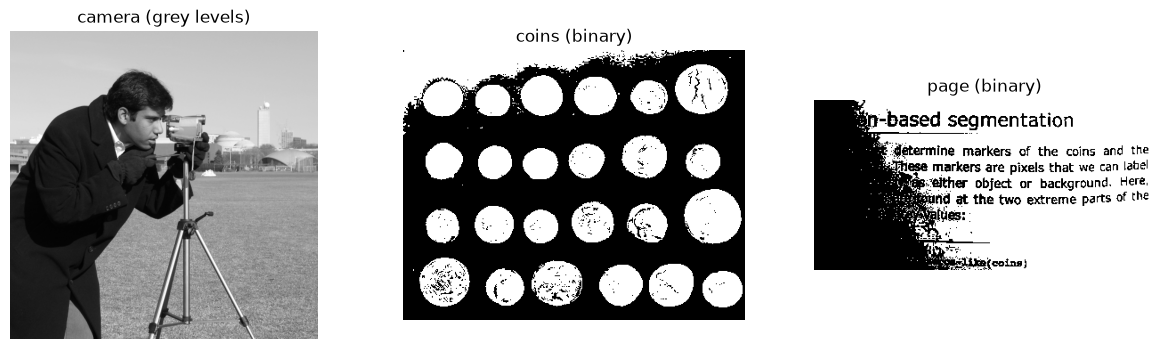

camera (grey levels)    199017 runs    262144 ->  398034 bytes   ratio  0.66   lossless: True
coins (binary)            4862 runs    116352 ->    9724 bytes   ratio 11.97   lossless: True
page (binary)             5958 runs     73344 ->   11916 bytes   ratio  6.16   lossless: True


In [4]:
camera = data.camera()
_, coins_binary = cv2.threshold(data.coins(), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, page_binary = cv2.threshold(data.page(), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, img, title in zip(ax, [camera, coins_binary, page_binary],
                         ["camera (grey levels)", "coins (binary)", "page (binary)"]):
    a.imshow(img)
    a.set_title(title)
    a.axis("off")
plt.show()

report("camera (grey levels)", camera)
report("coins (binary)", coins_binary)
report("page (binary)", page_binary)

A ratio above 1 means the encoded data is smaller. On the photo RLE makes things worse:
neighbouring pixels in a grey-level image are similar but rarely exactly equal, so almost every
run has length 1 and costs two bytes instead of one. On the binary images there are long runs of
black and white and the data shrinks.